# **PharmaVision**
### Visual Defect Detection in Pills and Capsules

## Introduction

Pills and capsules can develop visible defects during manufacturing and handling, a pill may have a crack, a capsule may get scratched, or a printed marking may appear incomplete. PharmaVision explores how a camera and a computer vision model could help flag these issues during visual quality inspection.

The system takes an image of a pill or capsule and produces two outputs: an **anomaly score** that indicates how unusual the item looks and a **heatmap** that shows which areas contributed to that score. For example, if a capsule has a scratch, the goal is to flag the capsule for review and highlight the scratch.

## Dataset and Approach

We use the **Pill** and **Capsule** categories from the **MVTec Anomaly Detection (MVTec AD)** dataset. Together, they provide **486 defect-free training images**. The dataset also includes normal and defective evaluation images, with **ground-truth masks** that mark the location of each annotated defect.

Our approach is **visual anomaly detection**. We plan to use **PatchCore** to learn what small regions of normal pills and capsules look like. When a new image is inspected, regions that differ from the normal examples receive higher anomaly scores. This lets us train using defect-free images and evaluate how well the model responds to different defects, including cracks, scratches, and faulty imprints.

## Project Objectives

1. **Explore and prepare the data** by checking image quality, reviewing defect examples, and preparing the training, validation, and test sets.
2. **Detect defective items** by using anomaly scores to distinguish normal images from defective ones.
3. **Locate visible defects** by comparing model heatmaps with ground-truth masks.
4. **Analyze the results** for pills and capsules to understand which defects the model detects well and which ones it tends to miss.

**Prepared by Fay, Lujain, Layan, and Muhammed**

# **1. Import Libraries**

In [ ]:
!pip install -q "kagglehub>=0.4.1" albumentations opencv-python-headless anomalib==2.7.1

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [ ]:
# File handling
import json
import shutil
from copy import deepcopy
from pathlib import Path

# Dataset loading and image processing
import albumentations as A
import cv2
import kagglehub
import numpy as np
import pandas as pd
from PIL import Image
from tqdm.auto import tqdm

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Dataset splitting and evaluation
from sklearn.metrics import balanced_accuracy_score
from sklearn.model_selection import train_test_split

# Whole-image baseline and autoencoder
import torch
from torch import nn
from torch.utils.data import DataLoader
from torchvision.models import ResNet18_Weights, resnet18

# PatchCore
from anomalib.data import Folder
from anomalib.deploy import ExportType
from anomalib.engine import Engine
from anomalib.models import Patchcore
from lightning.pytorch import seed_everything

/usr/local/lib/python3.13/dist-packages/timm/models/layers/__init__.py:49: FutureWarning: Importing from timm.models.layers is deprecated, please import via timm.layers
  warnings.warn(f"Importing from {__name__} is deprecated, please import via timm.layers", FutureWarning)
/usr/local/lib/python3.13/dist-packages/anomalib/models/image/dinomaly/components/layers.py:22: FutureWarning: The anomalib.models.components.dinov2 package is deprecated and will be removed in a future release. Please use the timm-based feature extractor instead: anomalib.models.components.feature_extractors.TimmFeatureExtractor
  from anomalib.models.components.dinov2.layers import Attention, DropPath, LayerScale, MemEffAttention


# **2. Download and Inspect the Dataset**

### 2.1 Download the Dataset

In [ ]:
!pip install -q "kagglehub>=0.4.1"

path = kagglehub.dataset_download("ipythonx/mvtec-ad")
print("Dataset path:", path)

Using Colab cache for faster access to the 'mvtec-ad' dataset.
Dataset path: /kaggle/input/mvtec-ad


### 2.2 Check the Dataset Path and Contents

In [ ]:
# Convert the path returned into a Path object
DATASET_PATH = Path(path)

# Check whether the dataset folder exists
print("Dataset exists:", DATASET_PATH.is_dir())

# List the files and folders directly inside the dataset folder
print("\nDataset contents:")
for item in sorted(DATASET_PATH.iterdir()):
    print(item.name)

Dataset exists: True

Dataset contents:
bottle
cable
capsule
carpet
grid
hazelnut
leather
license.txt
metal_nut
pill
readme.txt
screw
tile
toothbrush
transistor
wood
zipper


### 2.3 Inspect the Pill and Capsule Folders

In [ ]:
# Select the two categories used in PharmaVision
categories = ["pill", "capsule"]

for category in categories:
    category_path = DATASET_PATH / category

    # Print the category name and check that its folder exists
    print(f"\n{category.upper()}")
    print("Exists:", category_path.is_dir())

    if category_path.is_dir():
        for item in sorted(category_path.iterdir()):
            print("-", item.name)


PILL
Exists: True
- ground_truth
- license.txt
- readme.txt
- test
- train

CAPSULE
Exists: True
- ground_truth
- license.txt
- readme.txt
- test
- train


### 2.4 Count Images and Masks

In [ ]:
IMAGE_EXTENSIONS = {".png", ".jpg", ".jpeg"}

# Count image files in a folder and its subfolders
def count_images(folder):
    return sum(
        1 for file in folder.rglob("*")
        if file.is_file() and file.suffix.lower() in IMAGE_EXTENSIONS
    )

# Print the image and mask counts for each category
for category in categories:
    print(f"\n{category.upper()}")

    for folder in ["train", "test", "ground_truth"]:
        folder_path = DATASET_PATH / category / folder

        if folder_path.is_dir():
            print(f"{folder}: {count_images(folder_path)}")
        else:
            print(f"{folder}: NOT FOUND")


PILL
train: 267
test: 167
ground_truth: 141

CAPSULE
train: 219
test: 132
ground_truth: 109


In [ ]:


dataset_summary = pd.DataFrame({
    "Category": ["Pill", "Capsule"],
    "Train Images": [267, 219],
    "Test Images": [167, 132],
    "Ground Truth Masks": [141, 109]
})

dataset_summary["Total Images"] = (
    dataset_summary["Train Images"] +
    dataset_summary["Test Images"]
)

display(dataset_summary)

print("\nTotal Training Images:",
      dataset_summary["Train Images"].sum())

print("Total Testing Images:",
      dataset_summary["Test Images"].sum())

print("Total Ground Truth Masks:",
      dataset_summary["Ground Truth Masks"].sum())

,Category,Train Images,Test Images,Ground Truth Masks,Total Images
0,Pill,267,167,141,434
1,Capsule,219,132,109,351



Total Training Images: 486
Total Testing Images: 299
Total Ground Truth Masks: 250


### 2.5 Preview Defect Counts

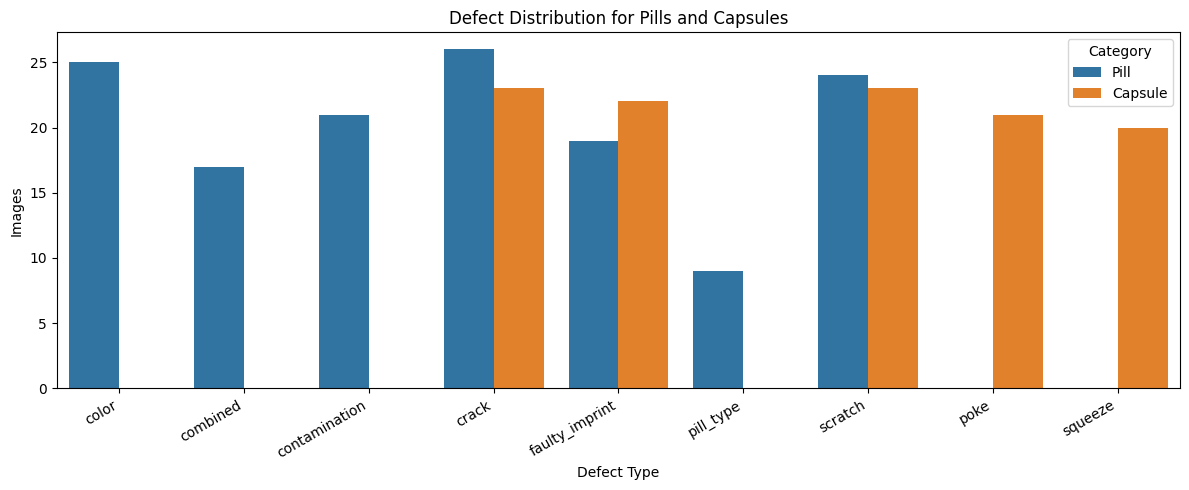

In [ ]:
defect_counts = []

# Collect the image count for each defect folder
for category in categories:
    test_path = DATASET_PATH / category / "test"

    for folder in sorted(test_path.iterdir()):
        if folder.is_dir() and folder.name != "good":
            defect_counts.append({
                "Category": category.capitalize(),
                "Defect Type": folder.name,
                "Images": count_images(folder),
            })

defect_summary = pd.DataFrame(defect_counts)

# Compare pill and capsule defect counts in one chart
plt.figure(figsize=(12, 5))
sns.barplot(
    data=defect_summary,
    x="Defect Type",
    y="Images",
    hue="Category",
)
plt.title("Defect Distribution for Pills and Capsules")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

- Pill has 7 defect types, Capsule has 5.
- Every defect class is small (9 to 26 images); `pill_type` is the rarest (9).

### 2.6 Preview Normal and Defective Images

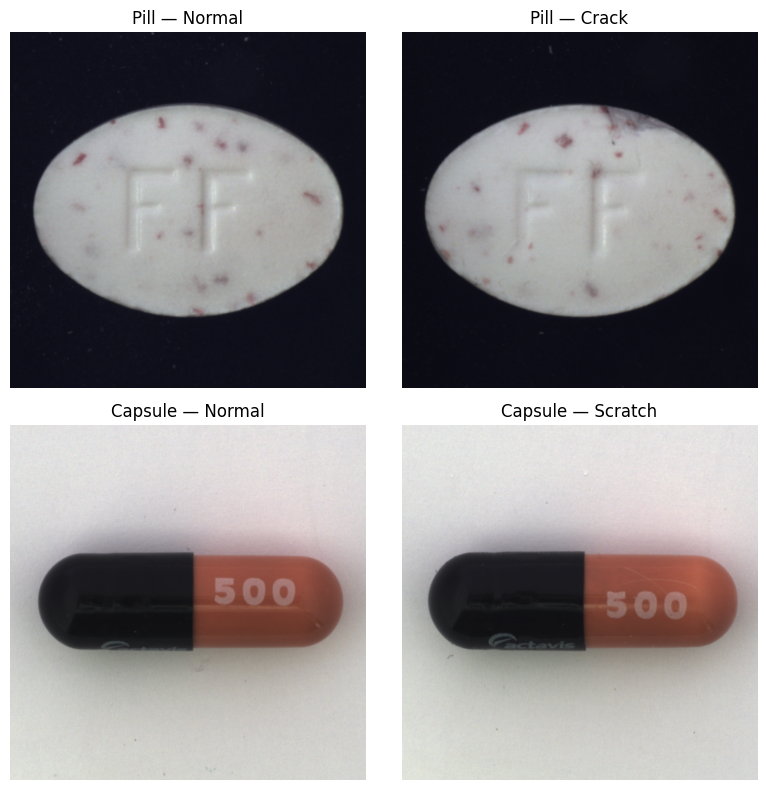

In [ ]:
# Choose one normal and one defective example for each category
examples = [
    ("pill", "good"),
    ("pill", "crack"),
    ("capsule", "good"),
    ("capsule", "scratch"),
]

fig, axes = plt.subplots(2, 2, figsize=(8, 8))

for ax, (category, defect_type) in zip(axes.flat, examples):
    folder = DATASET_PATH / category / "test" / defect_type

    # Pick the first image in the folder
    image_path = sorted(folder.glob("*.png"))[0]

    with Image.open(image_path) as image:
        ax.imshow(image.convert("RGB"))

    label = "Normal" if defect_type == "good" else defect_type.capitalize()
    ax.set_title(f"{category.capitalize()} — {label}")
    ax.axis("off")

plt.tight_layout()
plt.show()

### 2.7 Check Image and Mask Dimensions

In [ ]:
for category in categories:
    print(f"\n{category.upper()}")

    for split in ["train", "test", "ground_truth"]:
        folder = DATASET_PATH / category / split
        sizes = set()

        # Collect each unique (width, height) in this folder
        for image_path in folder.rglob("*.png"):
            with Image.open(image_path) as image:
                sizes.add(image.size)

        print(f"{split}: {sorted(sizes)}")


PILL
train: [(800, 800)]
test: [(800, 800)]
ground_truth: [(800, 800)]

CAPSULE
train: [(1000, 1000)]
test: [(1000, 1000)]
ground_truth: [(1000, 1000)]


### 2.8 Preview Typical Defect Sizes


In [ ]:
for category in categories:
    mask_folder = DATASET_PATH / category / "ground_truth"
    defect_areas = []

    for mask_path in mask_folder.rglob("*.png"):
        with Image.open(mask_path) as mask:
            pixels = np.array(mask.convert("L"))

        # Calculate the percentage of pixels marked as defective
        defect_percent = 100 * np.count_nonzero(pixels) / pixels.size
        defect_areas.append(defect_percent)

    print(f"{category.capitalize()}: median defect area = {np.median(defect_areas):.2f}%")

Pill: median defect area = 1.03%
Capsule: median defect area = 0.43%


The dataset contains normal and defective images of pills and capsules. The training set contains only normal images, and the test set includes several defect types. Ground-truth masks show where defects appear in the test images.

# **3. Data Quality Checks**

## 3.1 Check for Unreadable Files


In [ ]:
for category in categories:
    unreadable_files = []

    for folder in ["train", "test", "ground_truth"]:
        folder_path = DATASET_PATH / category / folder

        for image_path in folder_path.rglob("*.png"):
            try:
                with Image.open(image_path) as image:
                    image.load()
            except OSError:
                unreadable_files.append(image_path)

    print(f"{category.capitalize()}: {len(unreadable_files)} unreadable files")

    for image_path in unreadable_files:
        print(f"  {image_path.relative_to(DATASET_PATH)}")

Pill: 0 unreadable files
Capsule: 0 unreadable files


## 3.2 Verify Defect Masks

In [ ]:
for category in categories:
    category_path = DATASET_PATH / category
    missing_masks = 0
    size_mismatches = 0
    invalid_masks = 0
    empty_masks = 0  # Added

    for image_path in (category_path / "test").rglob("*.png"):
        defect_type = image_path.parent.name

        # Normal images do not have defect masks
        if defect_type == "good":
            continue

        mask_path = (
            category_path / "ground_truth" / defect_type
            / f"{image_path.stem}_mask.png"
        )

        if not mask_path.is_file():
            missing_masks += 1
            continue

        with Image.open(image_path) as image, Image.open(mask_path) as mask:
            if image.size != mask.size:
                size_mismatches += 1

            pixel_values = np.unique(np.array(mask.convert("L")))
            if not set(pixel_values).issubset({0, 255}):
                invalid_masks += 1

            # Added: an all-black mask marks no defect
            if np.all(pixel_values == 0):
                empty_masks += 1

    print(f"\n{category.capitalize()}")
    print("Missing masks:", missing_masks)
    print("Size mismatches:", size_mismatches)
    print("Masks with invalid pixel values:", invalid_masks)
    print("Empty masks:", empty_masks)  # Added


Pill
Missing masks: 0
Size mismatches: 0
Masks with invalid pixel values: 0
Empty masks: 0

Capsule
Missing masks: 0
Size mismatches: 0
Masks with invalid pixel values: 0
Empty masks: 0


All checked files were readable for both pills and capsules. Every defective test image had a matching mask with the same dimensions, and all masks used valid pixel values. We can use the masks to show defect locations and measure defect sizes in the EDA.

# **4. Exploratory Data Analysis (EDA)**

## 4.1 Visualize Defect Locations




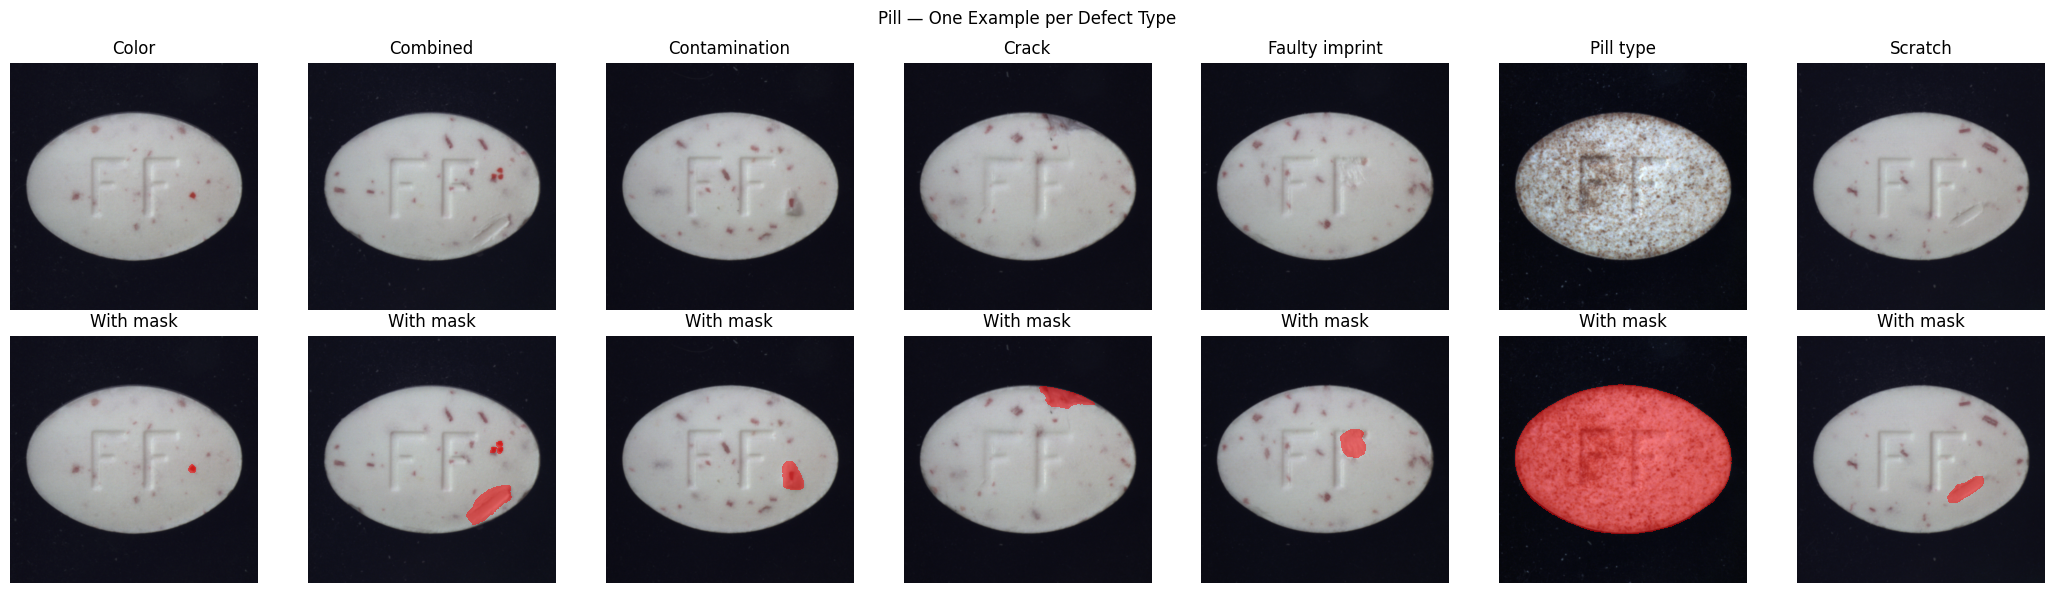

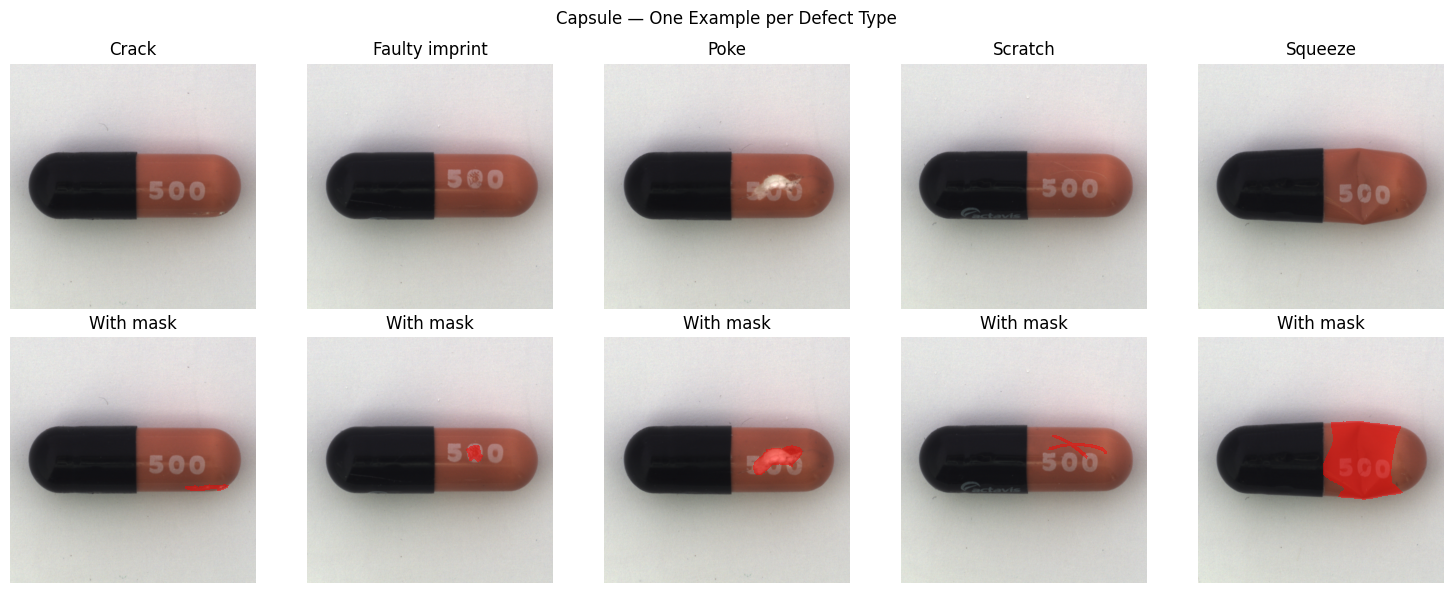

In [ ]:
FIG_DIR = Path("outputs") / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)


def show_defect_examples(category):
    category_path = DATASET_PATH / category

    # Each folder under ground_truth represents one defect type
    defect_folders = sorted(
        folder for folder in (category_path / "ground_truth").iterdir()
        if folder.is_dir()
    )

    fig, axes = plt.subplots(
        2, len(defect_folders),
        figsize=(3 * len(defect_folders), 6),
        squeeze=False,
    )

    for column, mask_folder in enumerate(defect_folders):
        defect_type = mask_folder.name
        image_folder = category_path / "test" / defect_type

        # Pick one image and find its matching mask
        image_path = sorted(image_folder.glob("*.png"))[0]
        mask_path = mask_folder / f"{image_path.stem}_mask.png"

        with Image.open(image_path) as image_file:
            image = image_file.convert("RGB")

        with Image.open(mask_path) as mask_file:
            mask = np.array(mask_file.convert("L"))

        original_ax, overlay_ax = axes[:, column]

        original_ax.imshow(image)
        original_ax.set_title(defect_type.replace("_", " ").capitalize())
        original_ax.axis("off")

        overlay_ax.imshow(image)
        overlay_ax.contourf(mask == 255, levels=[0.5, 1.5], colors=["red"], alpha=0.5)
        overlay_ax.set_title("With mask")
        overlay_ax.axis("off")

    fig.suptitle(f"{category.capitalize()} — One Example per Defect Type")
    fig.tight_layout()
    fig.savefig(FIG_DIR / f"defect_examples_{category}.png", bbox_inches="tight")
    plt.show()


for category in categories:
    show_defect_examples(category)

Most pill defects shown here affect a small area, such as a color spot, an edge crack, or part of the imprint. The `combined` example has multiple marked regions, and the `pill_type` mask covers nearly the entire pill.

## 4.2 Compare Defect Sizes by Type

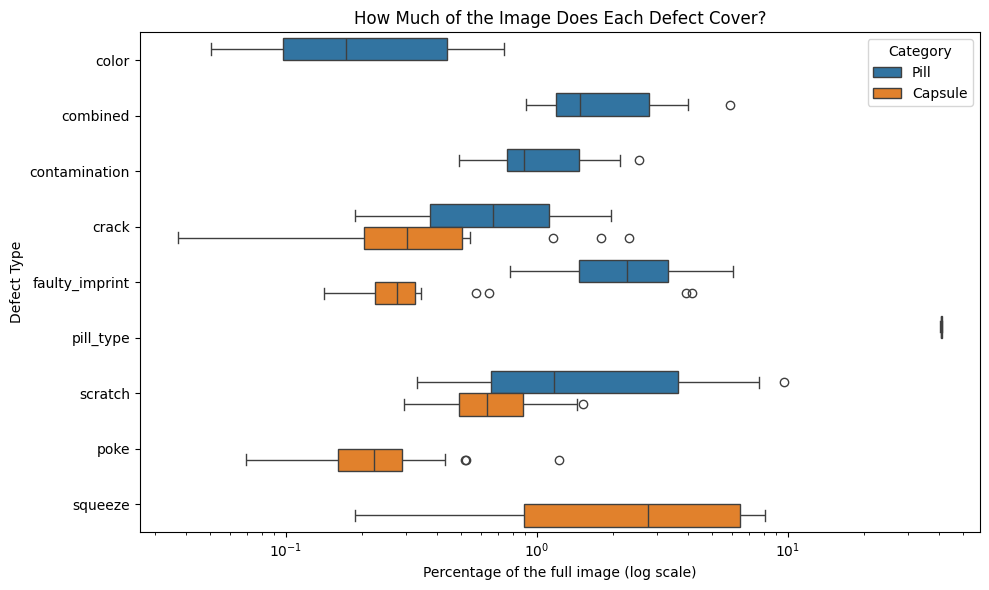

In [ ]:
defect_sizes = []

for category in categories:
    mask_folder = DATASET_PATH / category / "ground_truth"

    for mask_path in sorted(mask_folder.rglob("*.png")):
        with Image.open(mask_path) as mask:
            pixels = np.array(mask.convert("L"))

        # Divide the number of defect pixels by the total image pixels
        area_percent = 100 * (pixels == 255).mean()

        defect_sizes.append({
            "Category": category.capitalize(),
            "Defect Type": mask_path.parent.name,
            "Defect Area (%)": area_percent,
        })

defect_size_df = pd.DataFrame(defect_sizes)

plt.figure(figsize=(10, 6))
sns.boxplot(
    data=defect_size_df,
    x="Defect Area (%)",
    y="Defect Type",
    hue="Category",
)
plt.xscale("log")  # Spread out small percentages so they are easier to compare
plt.title("How Much of the Image Does Each Defect Cover?")
plt.xlabel("Percentage of the full image (log scale)")
plt.tight_layout()
plt.show()

Capsule cracks, scratches, and faulty imprints typically cover less of the image than the same defects on pills. The `pill_type` masks cover the largest area. During preprocessing, we’ll check whether thin scratches and small imprints are still visible after resizing.

## 4.3 Compare Image Brightness

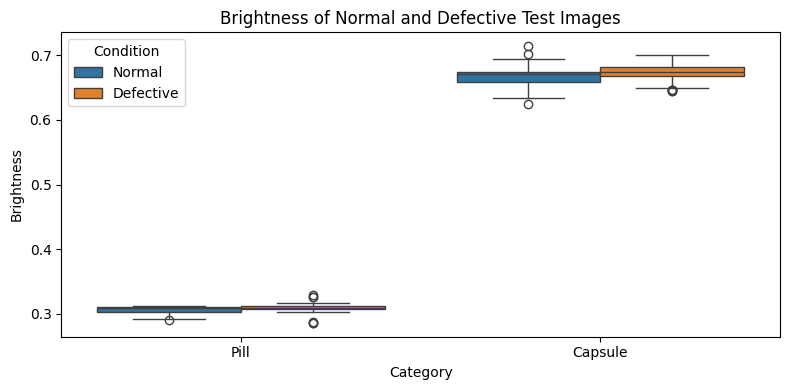

In [ ]:
rows = []

for category in categories:
    test_folder = DATASET_PATH / category / "test"

    for image_path in test_folder.rglob("*.png"):
        with Image.open(image_path) as image:
            brightness = np.asarray(image.convert("L")).mean() / 255

        rows.append({
            "Category": category.capitalize(),
            "Condition": "Normal" if image_path.parent.name == "good" else "Defective",
            "Brightness": brightness,
        })

brightness_df = pd.DataFrame(rows)

plt.figure(figsize=(8, 4))
sns.boxplot(data=brightness_df, x="Category", y="Brightness", hue="Condition")
plt.title("Brightness of Normal and Defective Test Images")
plt.tight_layout()
plt.show()

The mask overlays and size plot show that defects range from tiny spots to regions covering nearly the whole pill. Capsule cracks, scratches, and faulty imprints typically cover less of the image than the same defects on pills.

Capsule test images are brighter overall than pill images. Within each category, normal and defective images have similar brightness, so average brightness alone would be a weak signal for detecting defects.


# **5.Preprocessing**

### 5.1 Create Training, Validation, and Test Sets


In [ ]:
SEED = 42
split_rows = []

for category in categories:
    category_path = DATASET_PATH / category

    # Keep all official training images
    train_images = sorted((category_path / "train" / "good").glob("*.png"))

    # Split the official test images by folder label
    evaluation_images = sorted((category_path / "test").rglob("*.png"))
    val_images, test_images = train_test_split(
        evaluation_images,
        test_size=0.5,
        stratify=[path.parent.name for path in evaluation_images],
        random_state=SEED,
    )

    for split, images in [
        ("train", train_images),
        ("val", val_images),
        ("test", test_images),
    ]:
        for image_path in images:
            split_rows.append({
                "category": category,
                "split": split,
                "defect_type": image_path.parent.name,
                "image_path": image_path,
            })

split_df = pd.DataFrame(split_rows)

display(pd.crosstab(split_df["category"], split_df["split"]))

split,test,train,val
category,,,
capsule,66,219,66
pill,84,267,83


## 5.2 Resize and Normalize Images


In [ ]:
IMG_SIZE = 256
IMAGENET_MEAN = np.array([0.485, 0.456, 0.406], dtype=np.float32)
IMAGENET_STD = np.array([0.229, 0.224, 0.225], dtype=np.float32)


def preprocess_image(image_path):
    with Image.open(image_path) as image:
        image = image.convert("RGB").resize(
            (IMG_SIZE, IMG_SIZE), Image.Resampling.BILINEAR
        )
        pixels = np.asarray(image, dtype=np.float32) / 255.0

    return (pixels - IMAGENET_MEAN) / IMAGENET_STD


def preprocess_mask(mask_path):
    with Image.open(mask_path) as mask:
        mask = mask.convert("L").resize(
            (IMG_SIZE, IMG_SIZE), Image.Resampling.NEAREST
        )
        return (np.asarray(mask) == 255).astype(np.uint8)

## 5.3 Augment Normal Training Images

In [ ]:
output_dir = Path("/content/pharmavision_augmented")

transforms = {
    "rotation": A.Rotate(limit=5, border_mode=cv2.BORDER_REFLECT_101, p=1.0),
    "brightness": A.RandomBrightnessContrast(
        brightness_limit=0.08, contrast_limit=0.08, p=1.0
    ),
}

train_rows = split_df[
    (split_df["split"] == "train") & (split_df["defect_type"] == "good")
]
augmented_rows = []

for row in train_rows.to_dict("records"):
    image_path = row["image_path"]
    folder = output_dir / row["category"]
    folder.mkdir(parents=True, exist_ok=True)

    with Image.open(image_path) as image:
        pixels = np.array(image.convert("RGB"))

    for name, transform in transforms.items():
        augmented = transform(image=pixels)["image"]
        save_path = folder / f"{image_path.stem}_{name}.png"
        Image.fromarray(augmented).save(save_path)

        augmented_rows.append({**row, "image_path": save_path})

augmented_split_df = pd.concat(
    [split_df, pd.DataFrame(augmented_rows)], ignore_index=True
)

print("New training images:", len(augmented_rows))
print("Total training images:", len(train_rows) + len(augmented_rows))

New training images: 972
Total training images: 1458


## 6.Baseline: Whole-Image Nearest Neighbor

In [ ]:
import torch
from torchvision.models import ResNet18_Weights, resnet18



In [ ]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Load ResNet-18 and replace its classification layer with an identity layer
backbone = resnet18(weights=ResNet18_Weights.DEFAULT)
backbone.fc = torch.nn.Identity()
backbone = backbone.to(device).eval()
backbone.requires_grad_(False)

# Pick one original normal training image
image_path = split_df.loc[split_df["split"] == "train", "image_path"].iloc[0]

# Convert the preprocessed image to PyTorch format: (batch, channels, height, width)
image = torch.from_numpy(preprocess_image(image_path))
image = image.permute(2, 0, 1).unsqueeze(0).to(device)

with torch.inference_mode():
    features = backbone(image)

print("Image shape:", tuple(image.shape))
print("Feature shape:", tuple(features.shape))

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 193MB/s]


Image shape: (1, 3, 256, 256)
Feature shape: (1, 512)


In [ ]:
@torch.inference_mode()
def extract_image_features(image_paths, batch_size=16):
    batches = []

    for start in range(0, len(image_paths), batch_size):
        batch_paths = image_paths[start:start + batch_size]
        images = np.stack([preprocess_image(path) for path in batch_paths])

        # Convert from (batch, height, width, channels) to PyTorch format
        images = torch.from_numpy(images).permute(0, 3, 1, 2).to(device)
        batches.append(backbone(images).cpu())

    return torch.cat(batches)


normal_train = augmented_split_df[
    (augmented_split_df["split"] == "train")
    & (augmented_split_df["defect_type"] == "good")
]

baseline_banks = {}

for category in categories:
    image_paths = normal_train.loc[
        normal_train["category"] == category, "image_path"
    ].tolist()

    baseline_banks[category] = extract_image_features(image_paths)
    print(f"{category.capitalize()} bank: {tuple(baseline_banks[category].shape)}")

Pill bank: (801, 512)
Capsule bank: (657, 512)


In [ ]:
@torch.inference_mode()
def baseline_score(image_path, category):
    features = extract_image_features([image_path])
    distances = torch.cdist(features, baseline_banks[category])
    return distances.min().item()


# Try the scoring function on one validation image
example = split_df.loc[split_df["split"] == "val"].iloc[0]
score = baseline_score(example["image_path"], example["category"])

print("Category:", example["category"])
print("Dataset label:", example["defect_type"])
print(f"Anomaly score: {score:.4f}")

Category: pill
Dataset label: combined
Anomaly score: 5.6130


  0%|          | 0/149 [00:00<?, ?it/s]

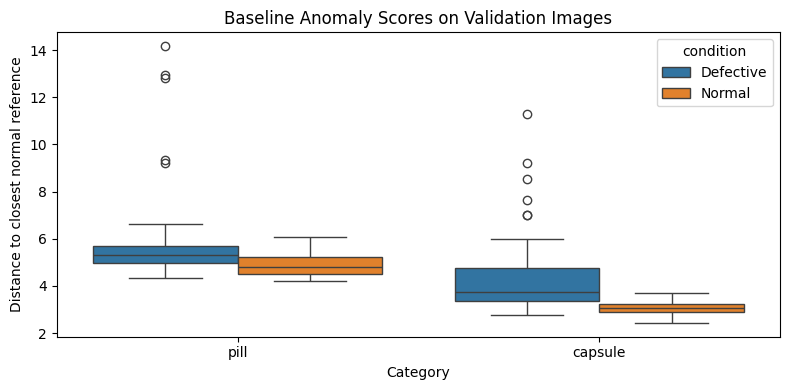

In [ ]:
baseline_val = split_df.loc[split_df["split"] == "val"].copy()

baseline_val["anomaly_score"] = [
    baseline_score(row.image_path, row.category)
    for row in tqdm(baseline_val.itertuples(index=False), total=len(baseline_val))
]

baseline_val["condition"] = np.where(
    baseline_val["defect_type"] == "good", "Normal", "Defective"
)

plt.figure(figsize=(8, 4))
sns.boxplot(
    data=baseline_val,
    x="category",
    y="anomaly_score",
    hue="condition",
)
plt.title("Baseline Anomaly Scores on Validation Images")
plt.xlabel("Category")
plt.ylabel("Distance to closest normal reference")
plt.tight_layout()
plt.show()

 Defective images tend to score higher than normal images within both categories. The scores still overlap, so some defects may be missed and some normal images may be flagged. Pill scores are generally higher than capsule scores, so we’ll choose a separate threshold for each category using the validation set.

In [ ]:
from sklearn.metrics import balanced_accuracy_score

In [ ]:
baseline_thresholds = {}

for category in categories:
    category_val = baseline_val[baseline_val["category"] == category]
    scores = category_val["anomaly_score"].to_numpy()
    actual_defect = category_val["defect_type"].to_numpy() != "good"

    # Try each observed score as a cutoff, plus a cutoff above all scores
    candidates = np.append(np.unique(scores), np.inf)
    accuracy_by_threshold = [
        balanced_accuracy_score(actual_defect, scores >= threshold)
        for threshold in candidates
    ]

    best_index = np.argmax(accuracy_by_threshold)
    baseline_thresholds[category] = candidates[best_index]

    print(f"{category.capitalize()} threshold: {baseline_thresholds[category]:.4f}")
    print(f"Validation balanced accuracy: {accuracy_by_threshold[best_index]:.2%}")

Pill threshold: 4.8222
Validation balanced accuracy: 68.35%
Capsule threshold: 3.2876
Validation balanced accuracy: 82.41%


The whole-image baseline reached **60.08% balanced accuracy for pills** and **70.91% for capsules**. It missed 13 pill defects and 12 capsule defects, and it falsely flagged 8 normal pills and 4 normal capsules. Test performance was lower than validation performance for both categories.

6.3 Convolutional Autoencoder

In [ ]:
from torch import nn

In [ ]:
def load_autoencoder_image(image_path):
    # Use the same 256 × 256 resize, then convert pixels to [0, 1]
    with Image.open(image_path) as image:
        image = image.convert("RGB").resize(
            (IMG_SIZE, IMG_SIZE), Image.Resampling.BILINEAR
        )
        pixels = np.array(image, dtype=np.float32) / 255.0

    return torch.from_numpy(pixels).permute(2, 0, 1)


encoder = nn.Sequential(
    nn.Conv2d(3, 16, kernel_size=4, stride=2, padding=1),
    nn.ReLU(),
    nn.Conv2d(16, 32, kernel_size=4, stride=2, padding=1),
    nn.ReLU(),
    nn.Conv2d(32, 32, kernel_size=4, stride=2, padding=1),
    nn.ReLU(),
)

decoder = nn.Sequential(
    nn.ConvTranspose2d(32, 32, kernel_size=4, stride=2, padding=1),
    nn.ReLU(),
    nn.ConvTranspose2d(32, 16, kernel_size=4, stride=2, padding=1),
    nn.ReLU(),
    nn.ConvTranspose2d(16, 3, kernel_size=4, stride=2, padding=1),
    nn.Sigmoid(),
)

autoencoder = nn.Sequential(encoder, decoder).to(device)

# Check the shapes with one normal training image
sample_path = split_df.loc[split_df["split"] == "train", "image_path"].iloc[0]
sample = load_autoencoder_image(sample_path).unsqueeze(0).to(device)

with torch.inference_mode():
    compressed = encoder(sample)
    reconstructed = decoder(compressed)

print("Input:", tuple(sample.shape))
print("Compressed:", tuple(compressed.shape))
print("Reconstruction:", tuple(reconstructed.shape))

Input: (1, 3, 256, 256)
Compressed: (1, 32, 32, 32)
Reconstruction: (1, 3, 256, 256)


In [ ]:
from copy import deepcopy
from torch.utils.data import DataLoader

In [ ]:
def load_image_batch(image_paths):
    return torch.stack([load_autoencoder_image(path) for path in image_paths])


autoencoders = {}
EPOCHS = 10

for category in categories:
    image_paths = normal_train.loc[
        normal_train["category"] == category, "image_path"
    ].tolist()

    loader = DataLoader(
        image_paths,
        batch_size=16,
        shuffle=True,
        collate_fn=load_image_batch,
    )

    # Start each category from the same untrained architecture and weights
    model = deepcopy(autoencoder).train()
    optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
    loss_fn = nn.MSELoss()

    print(f"\n{category.capitalize()} — {len(image_paths)} training images")

    for epoch in range(EPOCHS):
        total_loss = 0.0

        for images in loader:
            images = images.to(device)

            optimizer.zero_grad()
            reconstructed = model(images)
            loss = loss_fn(reconstructed, images)
            loss.backward()
            optimizer.step()

            total_loss += loss.item() * images.size(0)

        epoch_loss = total_loss / len(image_paths)
        print(f"Epoch {epoch + 1}/{EPOCHS}: MSE = {epoch_loss:.5f}")

    autoencoders[category] = model.eval()


Pill — 801 training images
Epoch 1/10: MSE = 0.04801
Epoch 2/10: MSE = 0.00483
Epoch 3/10: MSE = 0.00427
Epoch 4/10: MSE = 0.00386
Epoch 5/10: MSE = 0.00275
Epoch 6/10: MSE = 0.00107
Epoch 7/10: MSE = 0.00082
Epoch 8/10: MSE = 0.00066
Epoch 9/10: MSE = 0.00059
Epoch 10/10: MSE = 0.00051

Capsule — 657 training images
Epoch 1/10: MSE = 0.04788
Epoch 2/10: MSE = 0.01057
Epoch 3/10: MSE = 0.00292
Epoch 4/10: MSE = 0.00279
Epoch 5/10: MSE = 0.00198
Epoch 6/10: MSE = 0.00156
Epoch 7/10: MSE = 0.00137
Epoch 8/10: MSE = 0.00143
Epoch 9/10: MSE = 0.00107
Epoch 10/10: MSE = 0.00098


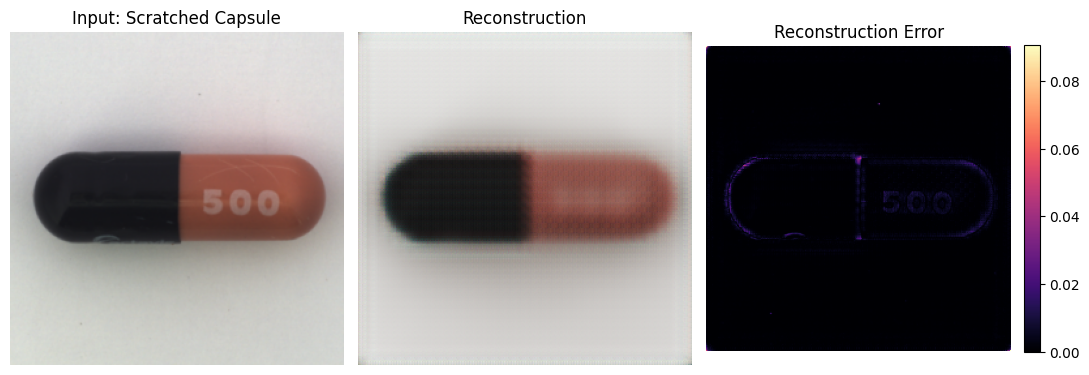

In [ ]:
example = split_df.loc[
    (split_df["split"] == "val")
    & (split_df["category"] == "capsule")
    & (split_df["defect_type"] == "scratch")
].iloc[0]

image = load_autoencoder_image(example["image_path"])

with torch.inference_mode():
    reconstruction = autoencoders["capsule"](
        image.unsqueeze(0).to(device)
    )[0].cpu()

# Average the squared error across the RGB channels
error_map = (image - reconstruction).square().mean(dim=0)

fig, axes = plt.subplots(1, 3, figsize=(11, 4))

axes[0].imshow(image.permute(1, 2, 0))
axes[0].set_title("Input: Scratched Capsule")

axes[1].imshow(reconstruction.permute(1, 2, 0))
axes[1].set_title("Reconstruction")

heatmap = axes[2].imshow(error_map, cmap="magma", vmin=0)
axes[2].set_title("Reconstruction Error")
fig.colorbar(heatmap, ax=axes[2], fraction=0.046, pad=0.04)

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

6. PatchCore Training

PatchCore learns what normal pills and capsules look like using a pretrained CNN. It stores features of the normal training images in a memory bank, then gives each new image an anomaly score and an anomaly map. We train one model for pills and one for capsules.



1 Install Anomalib

In [ ]:
!pip install -q anomalib==2.7.1

import shutil
from anomalib.data import Folder
from anomalib.models import Patchcore
from anomalib.engine import Engine
from anomalib.deploy import ExportType
from lightning.pytorch import seed_everything

6.2 Prepare the Folders

Anomalib reads images from folders, so we copy each split into its own folder. Defective images are renamed with their defect type (e.g. crack_000.png) so files don't overwrite each other.

In [ ]:
data_dir = Path("/content/patchcore_data")

for row in split_df.to_dict("records"):
    image_path = row["image_path"]
    folder = data_dir / row["category"]

    if row["split"] == "train":
        save_path = folder / "train" / image_path.name
    elif row["defect_type"] == "good":
        save_path = folder / row["split"] / "good" / image_path.name
    else:
        new_name = f"{row['defect_type']}_{image_path.name}"
        save_path = folder / row["split"] / "defect" / new_name

        # Copy the matching mask with the same name
        mask_path = DATASET_PATH / row["category"] / "ground_truth" / row["defect_type"] / f"{image_path.stem}_mask.png"
        mask_save = folder / row["split"] / "mask" / new_name
        mask_save.parent.mkdir(parents=True, exist_ok=True)
        shutil.copy(mask_path, mask_save)

    save_path.parent.mkdir(parents=True, exist_ok=True)
    shutil.copy(image_path, save_path)

6.3 Training Function

Backbone: wide_resnet50_2 pretrained on ImageNet, using layer2 and layer3 features.
Training images: normal training images plus the augmented images from section 5.3.
The validation set is used to measure image AUROC and set the threshold.

In [ ]:
def get_data(category, split):
    folder = data_dir / category
    return Folder(
        name=category,
        normal_dir=[folder / "train", output_dir / category],
        normal_test_dir=folder / split / "good",
        abnormal_dir=folder / split / "defect",
        mask_dir=folder / split / "mask",
        val_split_mode="same_as_test",
        train_batch_size=16,
        eval_batch_size=16,
        num_workers=2,
    )


def train_patchcore(category, image_size, coreset_ratio):
    seed_everything(SEED)
    model = Patchcore(
        backbone="wide_resnet50_2",
        layers=["layer2", "layer3"],
        coreset_sampling_ratio=coreset_ratio,
        pre_processor=Patchcore.configure_pre_processor(image_size=(image_size, image_size)),
    )
    engine = Engine(logger=False, enable_progress_bar=False)
    data = get_data(category, "val")

    engine.fit(model=model, datamodule=data)
    results = engine.test(model=model, datamodule=data)
    return model, engine, results[0]["image_AUROC"]

6.4 Compare Image Size and Coreset Ratio

In [ ]:
results = []
best_models = {}

for category in categories:
    best_auroc = 0
    for image_size in [224, 256]:
        for coreset_ratio in [0.01, 0.05]:
            model, engine, auroc = train_patchcore(category, image_size, coreset_ratio)
            print(category, image_size, coreset_ratio, "AUROC:", round(auroc, 4))
            results.append({
                "category": category,
                "image_size": image_size,
                "coreset_ratio": coreset_ratio,
                "val_image_AUROC": auroc,
            })
            # Keep only the best model for each category
            if auroc > best_auroc:
                best_auroc = auroc
                best_models[category] = (model, engine, image_size, coreset_ratio, auroc)

results_df = pd.DataFrame(results)
display(results_df)

INFO: Seed set to 42
INFO:lightning.fabric.utilities.seed:Seed set to 42


model.safetensors: reconstructing file:   0%|          |  0.00B /  276MB            

model.safetensors: downloading bytes:           |  0.00B            

INFO:lightning_fabric.utilities.rank_zero:GPU available: True (cuda), used: True
INFO:lightning_fabric.utilities.rank_zero:TPU available: False, using: 0 TPU cores
INFO:lightning_fabric.utilities.rank_zero:💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
INFO: LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
INFO:lightning.pytorch.accelerators.cuda:LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
/usr/local/lib/python3.13/dist-packages/lightning/pytorch/core/optimizer.py:183: `LightningModule.configure_optimizers` returned `None`, this fit will run with no optimizer


┏━━━┳━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━┳━━━━━━━━┳━━━━━━━┳━━━━━━━┓
┃   ┃ Name           ┃ Type           ┃ Params ┃ Mode  ┃ FLOPs ┃
┡━━━╇━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━╇━━━━━━━━╇━━━━━━━╇━━━━━━━┩
│ 0 │ pre_processor  │ PreProcessor   │      0 │ train │     0 │
│ 1 │ post_processor │ PostProcessor  │      0 │ train │     0 │
│ 2 │ evaluator      │ Evaluator      │      0 │ train │     0 │
│ 3 │ model          │ PatchcoreModel │ 24.9 M │ train │     0 │
└───┴────────────────┴────────────────┴────────┴───────┴───────┘

Trainable params: 24.9 M                                                                                           
Non-trainable params: 0                                                                                            
Total params: 24.9 M                                                                                               
Total estimated model params size (MB): 99.450                                                                     
Modules in train mode: 19                                                                                          
Modules in eval mode: 174                                                                                          
Total FLOPs: 0

... (49 outputs left out)

/usr/local/lib/python3.13/dist-packages/lightning/pytorch/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.
/usr/local/lib/python3.13/dist-packages/lightning/pytorch/loops/fit_loop.py:538: Found 174 module(s) in eval mode at the start of training. This may lead to unexpected behavior during training. If this is intentional, you can ignore this warning.
Selecting Coreset Indices.: 100%|██████████| 33637/33637 [07:01<00:00, 79.73it/s]
INFO:lightning_fabric.utilities.rank_zero:`Trainer.fit` stopped: `max_epochs=1` reached.
INFO:lightning_fabric.utilities.rank_zero:The following callbacks returned in `LightningModule.configure_callbacks` will override existing callbacks passed to Trainer: Evaluator, ImageVisualizer, PostProcessor, PreProcessor
INFO: LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
INFO:lightning.pytorch.accelerators.cuda:LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]


┏━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃        Test metric        ┃       DataLoader 0        ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│        image_AUROC        │    0.9922839403152466     │
│       image_F1Score       │    0.9719626307487488     │
│        pixel_AUROC        │    0.9892270565032959     │
│       pixel_F1Score       │    0.5126023888587952     │
└───────────────────────────┴───────────────────────────┘

capsule 256 0.05 AUROC: 0.9923


,category,image_size,coreset_ratio,val_image_AUROC
0,pill,224,0.01,0.939560
1,pill,224,0.05,0.949450
2,pill,256,0.01,0.951648
3,pill,256,0.05,0.947253
4,capsule,224,0.01,0.962963
5,capsule,224,0.05,0.972222
6,capsule,256,0.01,0.990741
7,capsule,256,0.05,0.992284


In [ ]:
# Keep the best setting for each category
best = results_df.sort_values("val_image_AUROC", ascending=False).groupby("category").head(1)
display(best)

,category,image_size,coreset_ratio,val_image_AUROC
7,capsule,256,0.05,0.992284
2,pill,256,0.01,0.951648


6.5 Train and Save the Final Models

In [ ]:
model_dir = Path("outputs") / "patchcore"
final_models = {}

for category in categories:
    model, engine, image_size, coreset_ratio, auroc = best_models[category]
    final_models[category] = (model, engine)

    save_dir = model_dir / category
    save_dir.mkdir(parents=True, exist_ok=True)

    # Save the checkpoint and an exported copy of the model
    engine.trainer.save_checkpoint(save_dir / "model.ckpt")
    engine.export(model=model, export_type=ExportType.TORCH, export_root=save_dir)

    # Save the settings used for this model
    config = {
        "category": category,
        "backbone": "wide_resnet50_2",
        "layers": ["layer2", "layer3"],
        "image_size": int(image_size),
        "coreset_ratio": float(coreset_ratio),
        "image_threshold": float(model.post_processor.image_threshold),
        "val_image_AUROC": float(auroc),
    }
    with open(save_dir / "config.json", "w") as f:
        json.dump(config, f, indent=2)

    print(category, "saved to", save_dir)

INFO: `weights_only` was not set, defaulting to `False`.
INFO:lightning.pytorch.trainer.connectors.checkpoint_connector:`weights_only` was not set, defaulting to `False`.
INFO: `weights_only` was not set, defaulting to `False`.
INFO:lightning.pytorch.trainer.connectors.checkpoint_connector:`weights_only` was not set, defaulting to `False`.


pill saved to outputs/patchcore/pill
capsule saved to outputs/patchcore/capsule


6.6 Anomaly Scores and Anomaly Maps
We save the anomaly score and anomaly map of every validation and test image for the evaluation step.

In [ ]:
for category, (model, engine) in final_models.items():
    for split in ["val", "test"]:
        data = get_data(category, split)
        data.setup()
        predictions = engine.predict(model=model, dataloaders=data.test_dataloader())

        scores = []
        maps = {}
        for batch in predictions:
            for i in range(len(batch.image_path)):
                name = Path(batch.image_path[i]).name
                scores.append({
                    "image": name,
                    "label": int(batch.gt_label[i]),
                    "anomaly_score": float(batch.pred_score[i]),
                    "prediction": int(batch.pred_label[i]),
                })
                maps[name] = batch.anomaly_map[i].squeeze().cpu().numpy()

        pd.DataFrame(scores).to_csv(model_dir / category / f"scores_{split}.csv", index=False)
        np.savez_compressed(model_dir / category / f"anomaly_maps_{split}.npz", **maps)
        print(category, split, len(scores), "images")

INFO:lightning_fabric.utilities.rank_zero:The following callbacks returned in `LightningModule.configure_callbacks` will override existing callbacks passed to Trainer: Evaluator, ImageVisualizer, PostProcessor, PreProcessor
INFO: LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
INFO:lightning.pytorch.accelerators.cuda:LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
/usr/local/lib/python3.13/dist-packages/lightning/pytorch/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.
INFO:lightning_fabric.utilities.rank_zero:The following callbacks returned in `LightningModule.configure_callbacks` will override existing callbacks passed to Trainer: Evaluator, ImageVisualizer, PostProcessor, PreProcessor
INFO: LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
INFO:lightning.pytorch.accelerators.cuda:LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]


pill val 83 images


/usr/local/lib/python3.13/dist-packages/lightning/pytorch/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.
INFO:lightning_fabric.utilities.rank_zero:The following callbacks returned in `LightningModule.configure_callbacks` will override existing callbacks passed to Trainer: Evaluator, ImageVisualizer, PostProcessor, PreProcessor
INFO: LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
INFO:lightning.pytorch.accelerators.cuda:LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]


pill test 84 images


/usr/local/lib/python3.13/dist-packages/lightning/pytorch/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.
INFO:lightning_fabric.utilities.rank_zero:The following callbacks returned in `LightningModule.configure_callbacks` will override existing callbacks passed to Trainer: Evaluator, ImageVisualizer, PostProcessor, PreProcessor
INFO: LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
INFO:lightning.pytorch.accelerators.cuda:LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]


capsule val 66 images


/usr/local/lib/python3.13/dist-packages/lightning/pytorch/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.


capsule test 66 images


In [ ]:
# Download the trained models and results
shutil.make_archive("patchcore_models", "zip", model_dir)

'/content/patchcore_models.zip'

## 7. Model Evaluation

7.1 Image-Level Evaluation

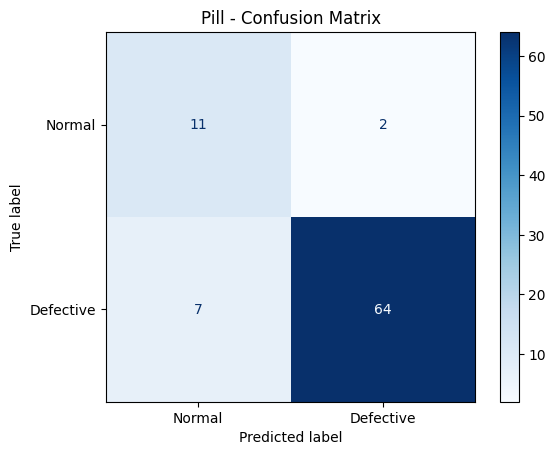

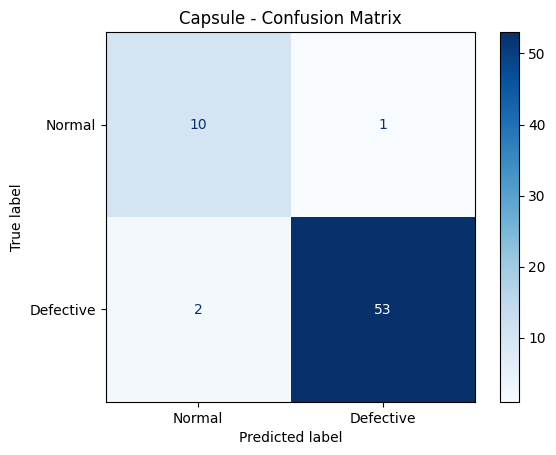

,Category,AUROC,Precision,Recall,F1
0,pill,0.9469,0.9697,0.9014,0.9343
1,capsule,0.9967,0.9815,0.9636,0.9725


In [ ]:

from sklearn.metrics import (
    roc_auc_score, precision_score, recall_score,
    f1_score, confusion_matrix, ConfusionMatrixDisplay,
    balanced_accuracy_score
)

evaluation_results = []
patchcore_thresholds = {}

for category in ["pill", "capsule"]:
    folder = model_dir / category

    val = pd.read_csv(folder / "scores_val.csv")
    test = pd.read_csv(folder / "scores_test.csv")

    # Choose threshold using validation data only
    thresholds = np.unique(val["anomaly_score"])
    best_threshold = max(
        thresholds,
        key=lambda t: balanced_accuracy_score(
            val["label"],
            (val["anomaly_score"] >= t).astype(int)
        )
    )
    patchcore_thresholds[category] = best_threshold

    y_true = test["label"]
    y_pred = (test["anomaly_score"] >= best_threshold).astype(int)

    evaluation_results.append({
        "Category": category,
        "AUROC": roc_auc_score(y_true, test["anomaly_score"]),
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Recall": recall_score(y_true, y_pred, zero_division=0),
        "F1": f1_score(y_true, y_pred, zero_division=0)
    })

    ConfusionMatrixDisplay.from_predictions(
        y_true, y_pred,
        display_labels=["Normal", "Defective"],
        cmap="Blues"
    )
    plt.title(f"{category.capitalize()} - Confusion Matrix")
    plt.show()

results_df_eval = pd.DataFrame(evaluation_results)
display(results_df_eval.round(4))


7.2 Defect Localization

In [ ]:

from sklearn.metrics import roc_auc_score

localization_results = []

for category in ["pill", "capsule"]:
    folder = model_dir / category
    maps = np.load(folder / "anomaly_maps_test.npz")

    true_pixels = []
    predicted_pixels = []

    for image_name in maps.files:
        image_path = data_dir / category / "test" / "defect" / image_name

        # Only defective images have ground-truth defect masks
        if not image_path.exists():
            continue

        mask_path = data_dir / category / "test" / "mask" / image_name

        if not mask_path.exists():
            continue

        anomaly_map = maps[image_name].squeeze()
        height, width = anomaly_map.shape

        mask = cv2.imread(str(mask_path), cv2.IMREAD_GRAYSCALE)
        mask = cv2.resize(
            mask, (width, height),
            interpolation=cv2.INTER_NEAREST
        )

        true_pixels.extend((mask > 0).ravel())
        predicted_pixels.extend(anomaly_map.ravel())

    pixel_auroc = roc_auc_score(
        true_pixels, predicted_pixels
    )

    localization_results.append({
        "Category": category,
        "Pixel AUROC": pixel_auroc
    })

display(pd.DataFrame(localization_results).round(4))

,Category,Pixel AUROC
0,pill,0.9809
1,capsule,0.9876


7.3 Visualize Defect Heatmaps

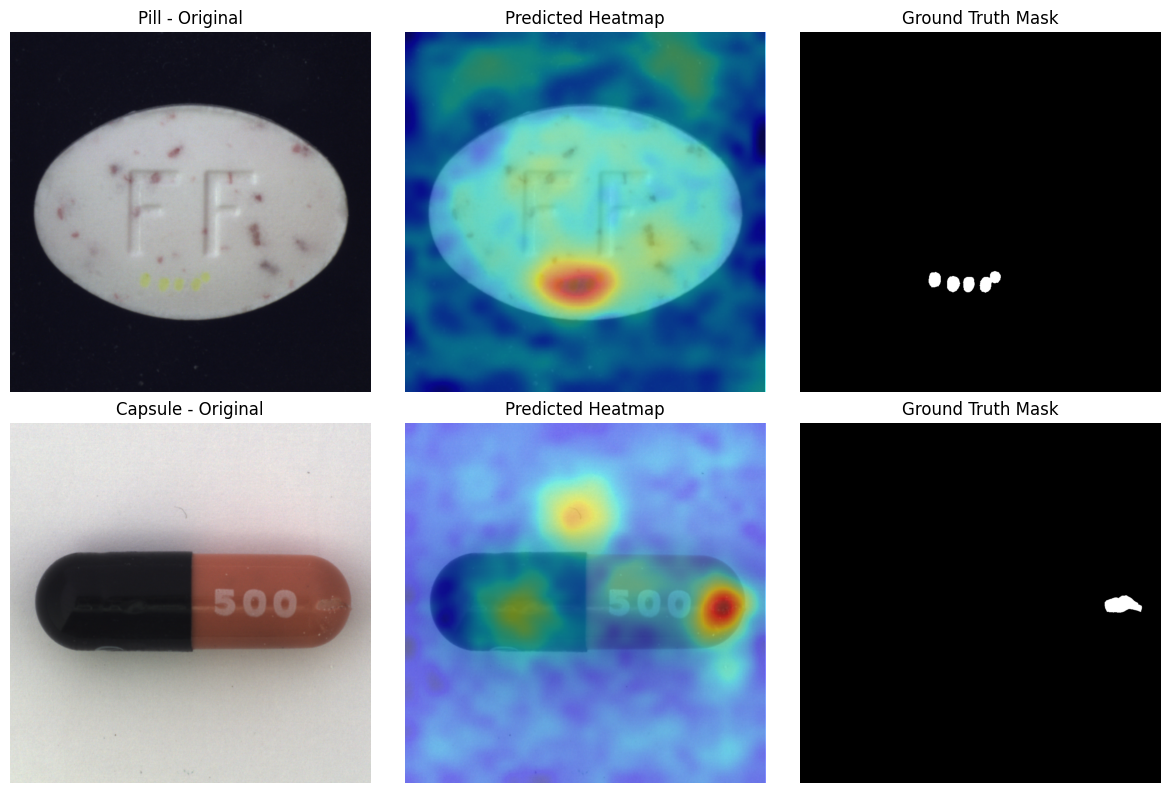

In [ ]:

fig, axes = plt.subplots(2, 3, figsize=(12, 8))

for row, category in enumerate(["pill", "capsule"]):
    folder = model_dir / category
    maps = np.load(folder / "anomaly_maps_test.npz")

    # Choose a defective sample
    image_name = next(
        name for name in maps.files
        if (data_dir / category / "test" / "defect" / name).exists()
    )

    image_path = data_dir / category / "test" / "defect" / image_name
    mask_path = data_dir / category / "test" / "mask" / image_name

    image = Image.open(image_path).convert("RGB")
    anomaly_map = maps[image_name].squeeze()
    mask = Image.open(mask_path).convert("L")

    axes[row, 0].imshow(image)
    axes[row, 0].set_title(f"{category.capitalize()} - Original")

    axes[row, 1].imshow(image)
    axes[row, 1].imshow(
        anomaly_map, cmap="jet", alpha=0.5,
        extent=(0, image.width, image.height, 0)
    )
    axes[row, 1].set_title("Predicted Heatmap")

    axes[row, 2].imshow(mask, cmap="gray")
    axes[row, 2].set_title("Ground Truth Mask")

for ax in axes.flat:
    ax.axis("off")

plt.tight_layout()
plt.show()

7.4 PatchCore vs Baseline

In [ ]:

comparison = []

for category in ["pill", "capsule"]:
    test_rows = split_df[
        (split_df["category"] == category) &
        (split_df["split"] == "test")
    ]

    y_true = (test_rows["defect_type"] != "good").astype(int)

    baseline_scores = [
        baseline_score(path, category)
        for path in tqdm(test_rows["image_path"])
    ]

    baseline_pred = (
        np.array(baseline_scores) >= baseline_thresholds[category]
    ).astype(int)

    patchcore_row = results_df_eval[
        results_df_eval["Category"] == category
    ].iloc[0]

    comparison.extend([
        {
            "Category": category,
            "Model": "Baseline",
            "AUROC": roc_auc_score(y_true, baseline_scores),
            "F1": f1_score(y_true, baseline_pred, zero_division=0)
        },
        {
            "Category": category,
            "Model": "PatchCore",
            "AUROC": patchcore_row["AUROC"],
            "F1": patchcore_row["F1"]
        }
    ])

display(pd.DataFrame(comparison).round(4))

  0%|          | 0/84 [00:00<?, ?it/s]

  0%|          | 0/66 [00:00<?, ?it/s]

,Category,Model,AUROC,F1
0,pill,Baseline,0.7866,0.8507
1,pill,PatchCore,0.9469,0.9343
2,capsule,Baseline,0.8645,0.8654
3,capsule,PatchCore,0.9967,0.9725
